# KV-Capped Oracle: Concurrency-Aware Offloading for Long-Context Agentic Serving

### The Core Paradox
In `dataset_comparison_oracle.ipynb`, all four KV-cache eviction policies (`Baseline Full LRU`, `Full-Conv Oracle`, `Naive Paged LRU`, `Paged Oracle`) achieved nearly identical `MeanE2E` on **Exgentic SWE-bench** (`~1769–1774 s` at `64 GB`, `λ=0.15`), **and `48 GB` HBM actually beat `64 GB` HBM by ~40 seconds (`1734 s` vs `1774 s`)**.

### Why?
1. **PCIe isn't the bottleneck at `λ=0.15`:** Moving ~3 TB over ~3,600 s is `< 1 GB/s` on a `16+ GB/s` PCIe link (`St.STALL < 1%`), so smarter eviction alone can't move `MeanE2E`.
2. **HBM decode-bandwidth saturation (`a_resident`):** During autoregressive decode, the GPU's compute cores stream *every active conversation's private KV cache* (`~4.5 GB` at `37K` context) from HBM on **every single generated token**. Beyond `~8–10` active jobs (`~300K` resident tokens), aggregate throughput saturates while per-request token speed drops nearly in half.
3. **The Fix (`KV-Capped Oracle`):** Separate **active decoding concurrency** (`R_cap` / `B_cap`) from **HBM residency**:
   - Cap active `PREFILL`+`DECODE` KV tokens at the throughput-latency sweet spot.
   - Use the remaining `64 GB` HBM as a **warm pool for `St.TOOL` sessions** (offloading paged blocks to DRAM only when HBM fills) and admit waiting jobs **Shortest-KV-First**.

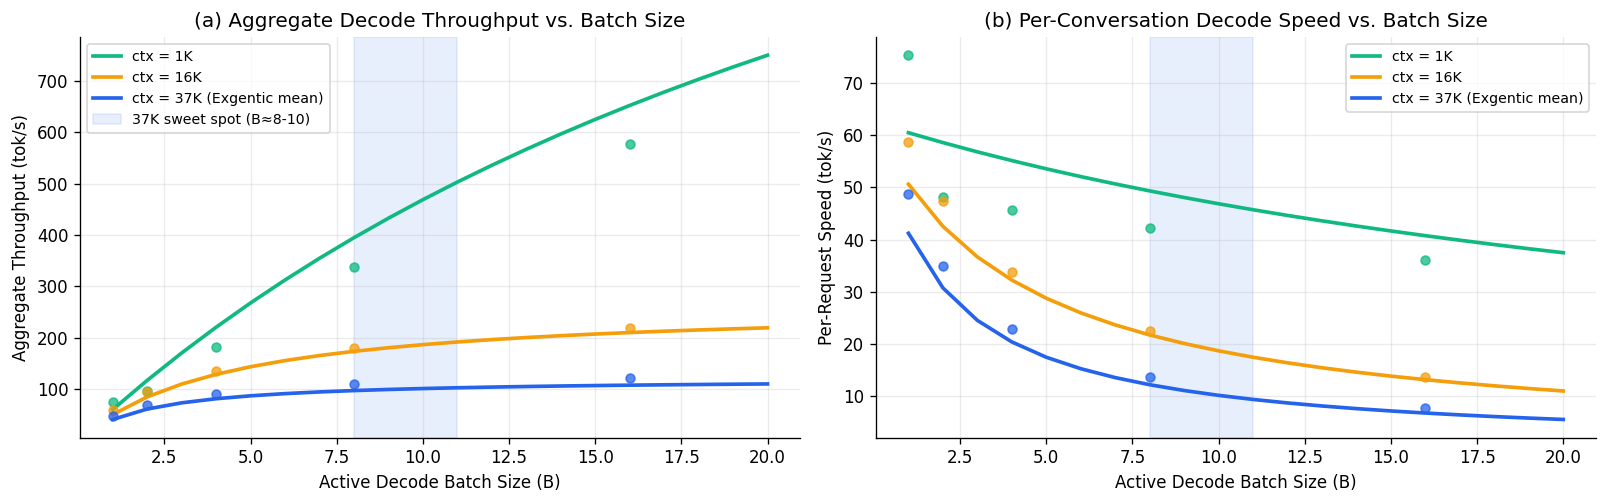

In [1]:
import json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

sys.path.insert(0, os.path.abspath(".."))
from sim.scheduler_sim import CostModel
from sim.paged_vs_oracle import run_capped_sim

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# 1. Hardware Characterization: CostModel decode throughput vs batch size
cm_path = "../results/sim_costmodel_h100_0905b.json"
cost = CostModel.from_calibration(cm_path)
raw_cm = json.load(open(cm_path))

batches = np.arange(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))

for ctx, col, lbl in [(1000, "#10b981", "ctx = 1K"), (16000, "#f59e0b", "ctx = 16K"), (37000, "#2563eb", "ctx = 37K (Exgentic mean)")]:
    dts = np.array([cost.step_time(int(b), int(b) * ctx, 0) for b in batches])
    axes[0].plot(batches, batches / dts, label=lbl, color=col, lw=2.2)
    axes[1].plot(batches, 1.0 / dts, label=lbl, color=col, lw=2.2)

for b, ctx, res, dt in raw_cm["decode_points"]:
    if b <= 20 and ctx in (974, 16117, 32291):
        c = {974: "#10b981", 16117: "#f59e0b", 32291: "#2563eb"}[ctx]
        axes[0].scatter([b], [b / dt], color=c, s=28, alpha=0.75, zorder=5)
        axes[1].scatter([b], [1.0 / dt], color=c, s=28, alpha=0.75, zorder=5)

axes[0].axvspan(8, 11, color="#2563eb", alpha=0.10, label="37K sweet spot (B≈8-10)")
axes[1].axvspan(8, 11, color="#2563eb", alpha=0.10)
axes[0].set_title("(a) Aggregate Decode Throughput vs. Batch Size")
axes[0].set_xlabel("Active Decode Batch Size (B)")
axes[0].set_ylabel("Aggregate Throughput (tok/s)")
axes[0].legend(fontsize=8.5)

axes[1].set_title("(b) Per-Conversation Decode Speed vs. Batch Size")
axes[1].set_xlabel("Active Decode Batch Size (B)")
axes[1].set_ylabel("Per-Request Speed (tok/s)")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

In [2]:
# 2. Parallel Sweep on Exgentic SWE-bench (64 GB, lambda=0.15)
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))

trace_path = "data/external_traces/exgentic_swebench.jsonl"
n_req, seed, max_time, rate, hbm = 40, 42, 5000.0, 0.15, 64.0

sweep_specs = [
    ("Baseline Full LRU",      "Baseline Full LRU",  {}),
    ("Paged Oracle (uncapped)","Paged Oracle (JIT)", {}),
    ("B_cap=12 (FIFO)",        "CappedPagedOracle",  {"b_cap": 12}),
    ("B_cap=10 (FIFO)",        "CappedPagedOracle",  {"b_cap": 10}),
    ("B_cap=8 (FIFO)",         "CappedPagedOracle",  {"b_cap": 8}),
    ("B_cap=6 (FIFO)",         "CappedPagedOracle",  {"b_cap": 6}),
    ("R_cap=200k (SJF)",       "CappedPagedOracle",  {"r_cap": 200_000, "sjf": True}),
    ("R_cap=250k (SJF)",       "CappedPagedOracle",  {"r_cap": 250_000, "sjf": True}),
    ("R_cap=300k (SJF)",       "CappedPagedOracle",  {"r_cap": 300_000, "sjf": True}),
    ("R_cap=350k (SJF)",       "CappedPagedOracle",  {"r_cap": 350_000, "sjf": True}),
    ("R_cap=400k (SJF)",       "CappedPagedOracle",  {"r_cap": 400_000, "sjf": True}),
    ("R_cap=450k (SJF)",       "CappedPagedOracle",  {"r_cap": 450_000, "sjf": True}),
]

tasks = [(lbl, bp, hbm, rate, n_req, seed, max_time, trace_path, kw) for lbl, bp, kw in sweep_specs]
sweep_res = {}
with ProcessPoolExecutor() as ex:
    for lbl, s in ex.map(run_capped_sim, tasks):
        sweep_res[lbl] = s

hdr = f"{'Policy':26s} | {'Done':5s} | {'MeanE2E':9s} | {'LastDone':9s} | {'EvictGB':9s} | {'TTFT':7s} | {'TTFTp95':8s} | {'HBM Wait':8s}"
print(hdr)
print("-" * len(hdr))
for lbl, _, _ in sweep_specs:
    s = sweep_res[lbl]
    print(f"{lbl:26s} | {s['done']:2d}/{s['total_requests']:2d} | {s['mean_e2e_s']:7.1f} s | "
          f"{s['makespan_done_s']:7.1f} s | {s['total_evicted_gb']:7.1f} G | "
          f"{s['ttft_mean']:5.2f} s | {s['ttft_p95']:6.2f} s | {s['hbm_wait_mean']:6.2f} s")

Policy                     | Done  | MeanE2E   | LastDone  | EvictGB   | TTFT    | TTFTp95  | HBM Wait
------------------------------------------------------------------------------------------------------
Baseline Full LRU          | 40/40 |  1773.7 s |  3638.5 s |  3358.9 G |  6.76 s |  21.40 s |   6.51 s
Paged Oracle (uncapped)    | 40/40 |  1768.9 s |  3646.3 s |  3097.8 G |  6.14 s |  25.56 s |   5.90 s
B_cap=12 (FIFO)            | 40/40 |  1670.4 s |  3832.0 s |   387.8 G |  5.27 s |  16.04 s |   5.13 s
B_cap=10 (FIFO)            | 40/40 |  1718.6 s |  3899.5 s |    86.2 G |  5.48 s |  21.18 s |   5.36 s
B_cap=8 (FIFO)             | 40/40 |  1845.0 s |  3960.5 s |    23.0 G |  6.97 s |  26.25 s |   6.86 s
B_cap=6 (FIFO)             | 40/40 |  2003.1 s |  4274.9 s |     0.0 G |  8.66 s |  29.90 s |   8.56 s
R_cap=200k (SJF)           | 40/40 |  1935.4 s |  4387.1 s |    64.3 G | 13.04 s |  40.71 s |  12.93 s
R_cap=250k (SJF)           | 40/40 |  1742.0 s |  3943.5 s |   177.9 G | 

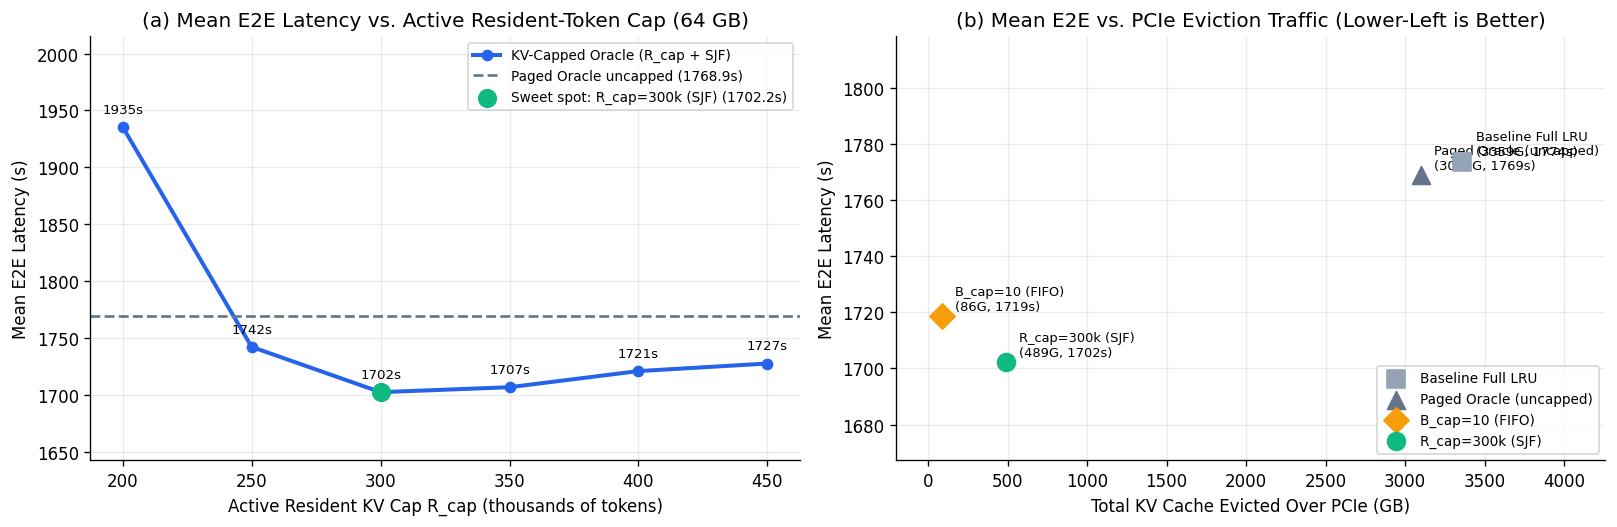

In [3]:
# 3. U-Curve & Eviction-Latency Pareto Plot
r_caps = [200, 250, 300, 350, 400, 450]
r_labels = [f"R_cap={r}k (SJF)" for r in r_caps]
r_e2e = [sweep_res[l]["mean_e2e_s"] for l in r_labels]

best_r_lbl = min(r_labels, key=lambda l: sweep_res[l]["mean_e2e_s"])
uncap_e2e = sweep_res["Paged Oracle (uncapped)"]["mean_e2e_s"]

fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.5))

axes[0].plot(r_caps, r_e2e, marker="o", lw=2.4, color="#2563eb", label="KV-Capped Oracle (R_cap + SJF)")
axes[0].axhline(uncap_e2e, color="#64748b", ls="--", lw=1.6, label=f"Paged Oracle uncapped ({uncap_e2e:.1f}s)")
best_idx = r_labels.index(best_r_lbl)
axes[0].scatter([r_caps[best_idx]], [r_e2e[best_idx]], color="#10b981", s=110, zorder=6,
                label=f"Sweet spot: {best_r_lbl} ({r_e2e[best_idx]:.1f}s)")
for x_v, y_v in zip(r_caps, r_e2e):
    axes[0].text(x_v, y_v + 10, f"{y_v:.0f}s", ha="center", va="bottom", fontsize=8)
axes[0].set_title("(a) Mean E2E Latency vs. Active Resident-Token Cap (64 GB)")
axes[0].set_xlabel("Active Resident KV Cap R_cap (thousands of tokens)")
axes[0].set_ylabel("Mean E2E Latency (s)")
axes[0].set_ylim(min(r_e2e) - 60, max(r_e2e) + 80)
axes[0].legend(fontsize=8.2)

pareto_items = [
    ("Baseline Full LRU",       "#94a3b8", "s"),
    ("Paged Oracle (uncapped)", "#64748b", "^"),
    ("B_cap=10 (FIFO)",         "#f59e0b", "D"),
    (best_r_lbl,                "#10b981", "o"),
]
for lbl, col, mk in pareto_items:
    s = sweep_res[lbl]
    axes[1].scatter([s["total_evicted_gb"]], [s["mean_e2e_s"]], color=col, marker=mk, s=115, label=lbl, zorder=5)
    axes[1].annotate(f"{lbl}\n({s['total_evicted_gb']:.0f}G, {s['mean_e2e_s']:.0f}s)",
                     (s["total_evicted_gb"], s["mean_e2e_s"]),
                     textcoords="offset points", xytext=(8, 4), fontsize=7.8)

axes[1].set_title("(b) Mean E2E vs. PCIe Eviction Traffic (Lower-Left is Better)")
axes[1].set_xlabel("Total KV Cache Evicted Over PCIe (GB)")
axes[1].set_ylabel("Mean E2E Latency (s)")
axes[1].set_xlim(-200, max(sweep_res[l]["total_evicted_gb"] for l, _, _ in pareto_items) + 900)
axes[1].set_ylim(min(sweep_res[l]["mean_e2e_s"] for l, _, _ in pareto_items) - 35,
                 max(sweep_res[l]["mean_e2e_s"] for l, _, _ in pareto_items) + 45)
axes[1].legend(fontsize=8.2, loc="lower right")

plt.tight_layout()
plt.show()

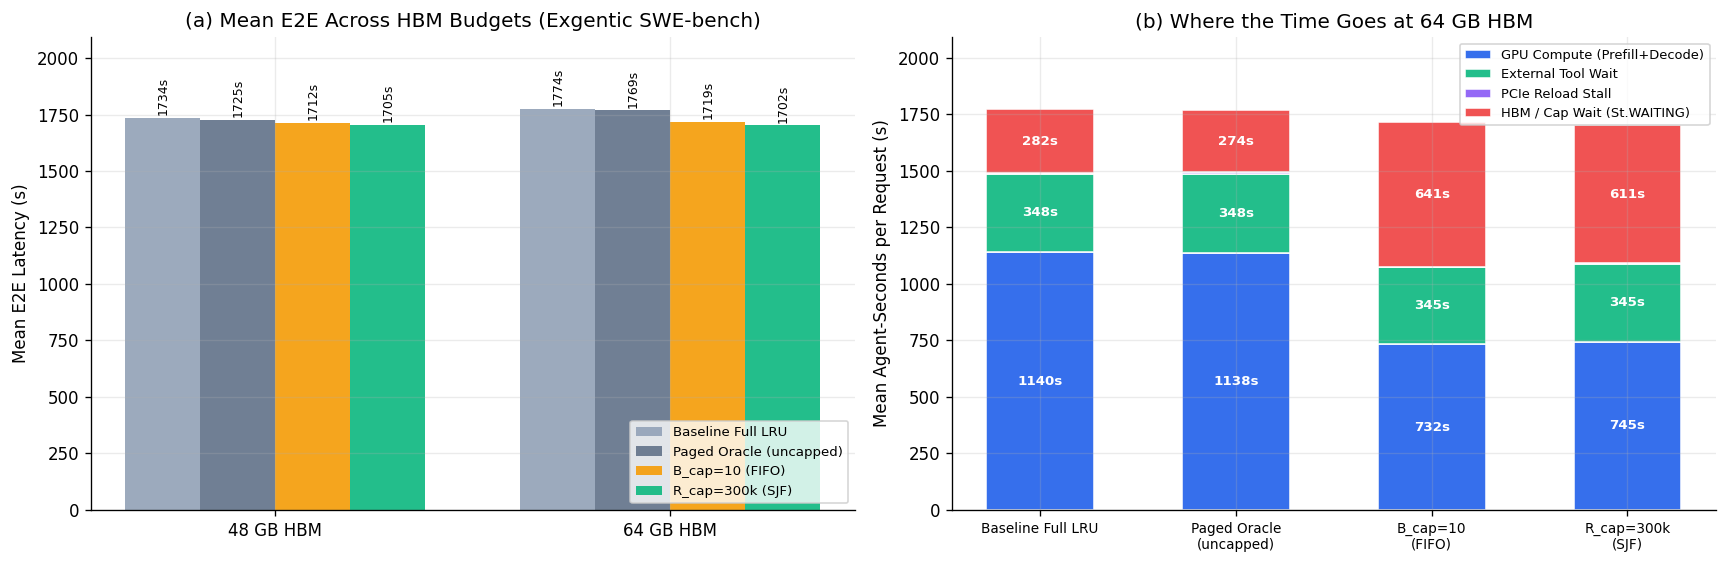

In [4]:
# 4. Multi-Budget Verification (48 GB vs 64 GB) + State-Time Breakdown
best_kw = dict(sweep_specs[[x[0] for x in sweep_specs].index(best_r_lbl)][2])
comp_policies = [
    ("Baseline Full LRU",       "Baseline Full LRU",  {}, "#94a3b8"),
    ("Paged Oracle (uncapped)", "Paged Oracle (JIT)", {}, "#64748b"),
    ("B_cap=10 (FIFO)",         "CappedPagedOracle",  {"b_cap": 10}, "#f59e0b"),
    (best_r_lbl,                "CappedPagedOracle",  best_kw, "#10b981"),
]

multi_tasks = []
for h in [48.0, 64.0]:
    for lbl, bp, kw, _ in comp_policies:
        multi_tasks.append((f"{h:.0f}G|{lbl}", bp, h, rate, n_req, seed, max_time, trace_path, kw))

multi_res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, multi_tasks):
        multi_res[k] = s

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))

hbms = [48.0, 64.0]
x = np.arange(len(hbms))
w = 0.19
offs = [-1.5*w, -0.5*w, 0.5*w, 1.5*w]
for off, (lbl, _, _, col) in zip(offs, comp_policies):
    vals = [multi_res[f"{h:.0f}G|{lbl}"]["mean_e2e_s"] for h in hbms]
    axes[0].bar(x + off, vals, w, label=lbl, color=col, alpha=0.92)
    for xi, v in zip(x, vals):
        axes[0].text(xi + off, v + 12, f"{v:.0f}s", ha="center", va="bottom", fontsize=7.5, rotation=90)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["48 GB HBM", "64 GB HBM"])
axes[0].set_ylabel("Mean E2E Latency (s)")
axes[0].set_title("(a) Mean E2E Across HBM Budgets (Exgentic SWE-bench)")
axes[0].set_ylim(0, max(multi_res[k]["mean_e2e_s"] for k in multi_res) * 1.18)
axes[0].legend(fontsize=8.0, loc="lower right")

bar_lbls, comp_s, tool_s, stall_s, wait_s = [], [], [], [], []
for lbl, _, _, _ in comp_policies:
    ss = multi_res[f"64G|{lbl}"]["state_seconds"]
    n_tot = float(multi_res[f"64G|{lbl}"]["total_requests"])
    bar_lbls.append(lbl.replace(" (uncapped)", "\n(uncapped)").replace(" (SJF)", "\n(SJF)").replace(" (FIFO)", "\n(FIFO)"))
    comp_s.append((ss["DECODE"] + ss["PREFILL"]) / n_tot)
    tool_s.append(ss["TOOL"] / n_tot)
    stall_s.append(ss["STALL"] / n_tot)
    wait_s.append(ss["WAITING"] / n_tot)

xb = np.arange(len(bar_lbls))
bot = np.zeros(len(bar_lbls))
for name, arr, col in [
    ("GPU Compute (Prefill+Decode)", comp_s, "#2563eb"),
    ("External Tool Wait",           tool_s, "#10b981"),
    ("PCIe Reload Stall",            stall_s, "#8b5cf6"),
    ("HBM / Cap Wait (St.WAITING)",  wait_s, "#ef4444"),
]:
    a = np.array(arr)
    axes[1].bar(xb, a, width=0.55, bottom=bot, label=name, color=col, alpha=0.92, edgecolor="white")
    for xi, v, b in zip(xb, a, bot):
        if v >= 90:
            axes[1].text(xi, b + v / 2.0, f"{v:.0f}s", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    bot += a
axes[1].set_xticks(xb)
axes[1].set_xticklabels(bar_lbls, fontsize=8.2)
axes[1].set_ylabel("Mean Agent-Seconds per Request (s)")
axes[1].set_title("(b) Where the Time Goes at 64 GB HBM")
axes[1].set_ylim(0, max(bot) * 1.18)
axes[1].legend(fontsize=7.8, loc="upper right")

plt.tight_layout()
plt.show()